# Exploratory Data Analysis: Dimuon Angular Distributions

This notebook extracts, analyzes, and visualizes the projected angular observables ($\theta_{XZ}$, $\theta_{YZ}$, and $\Delta\theta$) comparing **Signal** (direct charm decay: $\nu_\mu \to c \to \mu$) vs **Signal-Like** ($2\mu$ traversing DS) across 4 sequential stages of event selection and reconstruction:

1. **Stage 1: All Dimuon Events** (MC truth angles)
2. **Stage 2: Dimuons in DS Acceptance** (MC truth angles)
3. **Stage 3: Dimuons in DS Acceptance with $\ge 2$ Reconstructed DS Hough Tracks** (MC truth angles)
4. **Stage 4: Dimuons in DS Acceptance with $\ge 2$ Reconstructed DS Hough Tracks** (Reconstructed track angles: $\theta^{\mathrm{reco}}$ and $\Delta\theta^{\mathrm{reco}}$)

All conversions use `dur.converters.to_numpy` from `ddfUtils.root` directly. Plots compare **Signal** (solid black step) vs **Signal-Like** (tab:red markers) with clean legends and no floating text.

In [1]:
import os
import sys
import math
from typing import Dict, List, Tuple, Optional, Union

import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import ROOT

ROOT.gROOT.SetBatch(True)
ROOT.gStyle.SetOptStat(0)
ROOT.gStyle.SetOptTitle(0)

# Setup ddfUtils
_ddf_path = '/afs/cern.ch/user/i/idioniso/ddfUtils'
if _ddf_path not in sys.path and os.path.exists(_ddf_path):
    sys.path.insert(0, _ddf_path)

import ddfUtils.root as dur
import ddfUtils.mpl_styling as dms
hep.style.use(hep.style.ROOT)
print('Loaded ddfUtils.root (dur) and ddfUtils.mpl_styling (dms) with ROOT style.')


Loaded ddfUtils.root (dur) and ddfUtils.mpl_styling (dms) with ROOT style.


## 1. Histogram Lookup Utility

Helper function to recursively locate a histogram by name within a ROOT directory hierarchy.
Conversions to NumPy arrays use `dur.converters.to_numpy` directly from `ddfUtils.root`.

In [2]:
_HIST_CACHE: Dict[str, Dict[str, str]] = {}

def find_histogram(tfile: ROOT.TFile, hname: str) -> Optional[ROOT.TH1]:
    """Recursively finds a TH1 histogram by name within a ROOT TFile, using an in-memory path index for instant lookups."""
    if not tfile or tfile.IsZombie():
        return None

    obj = tfile.Get(hname)
    if obj and isinstance(obj, ROOT.TH1):
        return obj

    fname = tfile.GetName()
    if fname not in _HIST_CACHE:
        index = {}
        def build_index(d, prefix=""):
            for k in d.GetListOfKeys():
                name = k.GetName()
                path = f"{prefix}/{name}" if prefix else name
                cl = k.GetClassName()
                if "TDirectory" in cl:
                    sub = d.Get(name)
                    if sub:
                        build_index(sub, path)
                elif "TH" in cl:
                    index[name] = path
        build_index(tfile)
        _HIST_CACHE[fname] = index

    if hname in _HIST_CACHE[fname]:
        h_obj = tfile.Get(_HIST_CACHE[fname][hname])
        if h_obj and isinstance(h_obj, ROOT.TH1):
            return h_obj

    return None


## 2. Stage Plotting Function

`plot_stage_angular_distributions` plots the full 6-panel angular grid for a selected stage:
- **Pad 1 & 2**: $\theta_{XZ}(\mu_1)$ and $\theta_{XZ}(\mu_2)$ (log scale)
- **Pad 3 & 4**: $\theta_{YZ}(\mu_1)$ and $\theta_{YZ}(\mu_2)$ (log scale)
- **Pad 5 & 6**: $\Delta\theta_{XZ}$ and $\Delta\theta_{YZ}$ (linear scale)

In [3]:
STAGE_CONFIGS = {
    1: {
        'title': 'Stage 1: All Dimuon Events (MC Truth)',
        'sig_pref': 'direct',
        'bkg_pref': 'signal_like',
        'is_reco': False,
    },
    2: {
        'title': 'Stage 2: Dimuons in DS Acceptance (MC Truth)',
        'sig_pref': 'direct_in_acc',
        'bkg_pref': 'signal_like_in_acc',
        'is_reco': False,
    },
    3: {
        'title': 'Stage 3: In DS Acc + >=2 DS Tracks (MC Truth)',
        'sig_pref': 'direct_2ds_in_acc',
        'bkg_pref': 'signal_like_2ds_in_acc',
        'is_reco': False,
    },
    4: {
        'title': 'Stage 4: In DS Acc + >=2 DS Tracks (Reconstructed)',
        'sig_pref': 'direct_2ds_in_acc',
        'bkg_pref': 'signal_like_2ds_in_acc',
        'is_reco': True,
    },
}


def plot_stage_angular_distributions(
    input_file: Union[str, ROOT.TFile],
    stage: int = 1,
    sig_key: Optional[str] = None,
    bkg_key: Optional[str] = None,
    sig_label: str = 'numu -> c -> mu',
    bkg_label: str = 'Signal-Like (2 muons traversing DS)',
    figsize: Tuple[int, int] = (15, 12),
):
    """
    Reads ROOT file, extracts angular distributions for the specified stage using
    dur.converters.to_numpy, and plots all 6 distributions together in a 3x2 grid.
    """
    if stage not in STAGE_CONFIGS:
        raise ValueError(f'Invalid stage {stage}. Available: 1, 2, 3, 4')

    cfg = STAGE_CONFIGS[stage]
    spref = sig_key if sig_key else cfg['sig_pref']
    bpref = bkg_key if bkg_key else cfg['bkg_pref']
    is_reco = cfg['is_reco']
    stage_title = cfg['title']

    should_close = False
    if isinstance(input_file, str):
        f = ROOT.TFile.Open(input_file, 'READ')
        should_close = True
    else:
        f = input_file

    if not f or f.IsZombie():
        raise FileNotFoundError(f'Could not open input ROOT file: {input_file}')

    var_pfx = 'reco_' if is_reco else ''
    theta_sym = r'\theta^{\mathrm{reco}}' if is_reco else r'\theta'
    delta_sym = r'\Delta\theta^{\mathrm{reco}}' if is_reco else r'\Delta\theta'

    observables = [
        # (var_name, x_label, is_log, x_lim, y_lim)
        (f'{var_pfx}mu1_theta_xz_mrad', f'${theta_sym}_{{XZ}}(\mu_{{1}})$ [mrad]', True, (-300, 300), (0.5, 2e3)),
        (f'{var_pfx}sec_mu_theta_xz_mrad', f'${theta_sym}_{{XZ}}(\mu_{{2}})$ [mrad]', True, (-300, 300), (0.5, 5e2)),
        (f'{var_pfx}mu1_theta_yz_mrad', f'${theta_sym}_{{YZ}}(\mu_{{1}})$ [mrad]', True, (-300, 300), (0.5, 2e3)),
        (f'{var_pfx}sec_mu_theta_yz_mrad', f'${theta_sym}_{{YZ}}(\mu_{{2}})$ [mrad]', True, (-300, 300), (0.5, 5e2)),
        (f'{var_pfx}dimuon_opening_angle_xz_mrad', f'${delta_sym}_{{XZ}}$ [mrad]', False, (0, 300), (0, None)),
        (f'{var_pfx}dimuon_opening_angle_yz_mrad', f'${delta_sym}_{{YZ}}$ [mrad]', False, (0, 300), (0, None)),
    ]

    fig, axes = plt.subplots(3, 2, figsize=figsize)
    fig.suptitle(stage_title, fontsize=16, fontweight='bold', y=0.99)

    for idx, (var, xlabel, is_log, xlim, ylim) in enumerate(observables):
        ax = axes[idx // 2, idx % 2]
        h_sig = find_histogram(f, f'h_{spref}_{var}')
        h_bkg = find_histogram(f, f'h_{bpref}_{var}')

        if h_sig is None or h_bkg is None:
            ax.text(0.5, 0.5, f'Missing: {var}', ha='center', va='center', transform=ax.transAxes)
            continue

        # Use ddfUtils dur.converters.to_numpy
        centers_sig, counts_sig, edges_sig, _, errs_sig = dur.converters.to_numpy(h_sig)
        centers_bkg, counts_bkg, edges_bkg, _, errs_bkg = dur.converters.to_numpy(h_bkg)
        n_sig = int(h_sig.GetEntries())
        n_bkg = int(h_bkg.GetEntries())

        # Plot Signal: Solid Black Step line
        ax.step(
            edges_sig,
            np.append(counts_sig, counts_sig[-1]),
            where='post',
            color='black',
            linewidth=1.8,
            label=f'{sig_label} (N={n_sig})',
        )

        # Plot Background / Signal-Like: Red markers with error bars
        mask = counts_bkg > 0 if is_log else slice(None)
        ax.errorbar(
            centers_bkg[mask],
            counts_bkg[mask],
            yerr=errs_bkg[mask],
            fmt='o',
            color='tab:red',
            ecolor='tab:red',
            markersize=4,
            capsize=2,
            elinewidth=1.2,
            label=f'{bkg_label} (N={n_bkg})',
        )

        ax.set_xlabel(xlabel, fontsize=12)
        ax.set_ylabel('Events', fontsize=12)
        ax.set_xlim(xlim)

        if is_log:
            ax.set_yscale('log')
            max_val = max(counts_sig.max() if len(counts_sig) else 1,
                          counts_bkg.max() if len(counts_bkg) else 1)
            ax.set_ylim(0.5, max(max_val * 4.0, 10.0))
        else:
            max_val = max(counts_sig.max() if len(counts_sig) else 1,
                          counts_bkg.max() if len(counts_bkg) else 1)
            ax.set_ylim(0, max_val * 1.3)

        ax.legend(frameon=False, loc='upper right', fontsize=10)
        ax.grid(True, which='both', linestyle='--', alpha=0.5)

    plt.tight_layout()
    if should_close:
        f.Close()
    return fig, axes


## 3. Comparing Across All 4 Stages

`plot_all_stages_evolution` plots how a specific observable evolves from **Stage 1 to Stage 4** side-by-side in a 4-panel comparison.

### Physical and Algorithmic Definition of the Four Stages

1. **Stage 1: All Dimuon Events (MC Truth)**
   - Inclusive sample of all generated dimuon events inside the target fiducial volume at pure generator level (`MCTrack`).
   - No detector geometry or reconstruction requirements are imposed.

2. **Stage 2: Dimuons in DS Acceptance (MC Truth)**
   - Requires that **both truth muons** (prompt $\mu_1$ from the $\nu_\mu$ CC interaction and secondary $\mu_2$ from charm decay) geometrically traverse the active volume of the Downstream Muon Filter (`dimuon_in_ds_acceptance = mu1_in_ds && mu2_in_ds`).
   - *No tracking or hit reconstruction is required yet*; this isolates the pure geometric acceptance of the spectrometer.

3. **Stage 3: In DS Acc + $\ge 2$ DS Tracks (MC Truth)**
   - In addition to being in geometric acceptance, the event must have passed the detector response simulation and the SND@LHC reconstruction algorithm (`Reco_MuonTracks` Hough transform) must successfully reconstruct **at least two DS Hough tracks** (`has_two_ds_tracks == 1`).
   - **Crucially**, in Stage 3, the plotted kinematic angles are still evaluated from **MC Truth** (`MCTrack`).
   - **Difference between Stage 2 and Stage 3**: In Stage 2, both muons geometrically point into the detector, but the tracking algorithm may fail to reconstruct both tracks (due to detector hit inefficiencies, dead channels, track overlap/confusion in the dense hadronic shower core, or Hough pattern-recognition cuts). Comparing Stage 2 vs Stage 3 isolates the **reconstruction efficiency / event loss** without track resolution smearing.

4. **Stage 4: In DS Acc + $\ge 2$ DS Tracks (Reconstructed)**
   - Identical event sample to Stage 3 (`dimuon_in_ds_acceptance && has_two_ds_tracks == 1`), but the plotted angles are the **reconstructed track slopes** from `Reco_MuonTracks` ($\theta^{\mathrm{reco}}_{XZ}$, $\theta^{\mathrm{reco}}_{YZ}$, $\Delta\theta^{\mathrm{reco}}$).
   - Comparing Stage 3 vs Stage 4 isolates purely **detector resolution, track fitting biases, and angular smearing**.


In [4]:
def plot_all_stages_evolution(
    input_file: Union[str, ROOT.TFile],
    observable: str = 'dimuon_opening_angle_xz_mrad',
    obs_label: str = r'$\Delta\theta_{XZ}$ [mrad]',
    is_log: bool = False,
    xlim: Tuple[float, float] = (0, 300),
    sig_key: str = 'direct',
    bkg_key: str = 'signal_like',
    sig_label: str = 'numu -> c -> mu',
    bkg_label: str = 'Signal-Like',
    figsize: Tuple[int, int] = (18, 4.2),
):
    """Compares the distribution of an observable across the 4 stages side-by-side."""
    should_close = False
    if isinstance(input_file, str):
        f = ROOT.TFile.Open(input_file, 'READ')
        should_close = True
    else:
        f = input_file

    if not f or f.IsZombie():
        raise FileNotFoundError(f'Could not open input ROOT file: {input_file}')

    fig, axes = plt.subplots(1, 4, figsize=figsize, sharey=False)

    stage_suffixes = {1: '', 2: '_in_acc', 3: '_2ds_in_acc', 4: '_2ds_in_acc'}
    stage_is_reco = {1: False, 2: False, 3: False, 4: True}

    for stage_idx in range(1, 5):
        ax = axes[stage_idx - 1]
        cfg = STAGE_CONFIGS[stage_idx]
        suf = stage_suffixes[stage_idx]
        spref = f"{sig_key}{suf}"
        bpref = f"{bkg_key}{suf}"
        var_pfx = 'reco_' if stage_is_reco[stage_idx] else ''

        h_sig_name = f'h_{spref}_{var_pfx}{observable}'
        h_bkg_name = f'h_{bpref}_{var_pfx}{observable}'

        h_sig = find_histogram(f, h_sig_name)
        h_bkg = find_histogram(f, h_bkg_name)

        ax.set_title(cfg['title'], fontsize=10.5, fontweight='bold')
        
        counts_list = []
        if h_sig:
            centers_sig, counts_sig, edges_sig, _, _ = dur.converters.to_numpy(h_sig)
            n_sig = int(h_sig.GetEntries())
            ax.step(
                edges_sig,
                np.append(counts_sig, counts_sig[-1]),
                where='post',
                color='black',
                linewidth=1.8,
                label=f'{sig_label} (N={n_sig})',
            )
            counts_list.append(counts_sig)

        if h_bkg:
            centers_bkg, counts_bkg, edges_bkg, _, errs_bkg = dur.converters.to_numpy(h_bkg)
            n_bkg = int(h_bkg.GetEntries())
            mask = counts_bkg > 0 if is_log else slice(None)
            ax.errorbar(
                centers_bkg[mask],
                counts_bkg[mask],
                yerr=errs_bkg[mask],
                fmt='o',
                color='tab:red',
                markersize=4,
                capsize=2,
                elinewidth=1.2,
                label=f'{bkg_label} (N={n_bkg})',
            )
            counts_list.append(counts_bkg)

        if counts_list:
            max_val = max(c.max() if len(c) else 1.0 for c in counts_list)
            if is_log:
                ax.set_yscale('log')
                ax.set_ylim(0.5, max(max_val * 4.0, 10.0))
            else:
                ax.set_ylim(0, max_val * 1.3)
            ax.legend(frameon=False, fontsize=8.5, loc='upper right')

        label_to_use = obs_label
        if stage_is_reco[stage_idx] and r'\mathrm{reco}' not in obs_label:
            label_to_use = obs_label.replace(r'\theta', r'\theta^{\mathrm{reco}}')

        ax.set_xlabel(label_to_use, fontsize=11)
        ax.set_xlim(xlim)
        ax.grid(True, which='both', linestyle='--', alpha=0.5)

    axes[0].set_ylabel('Events', fontsize=12)
    plt.tight_layout()
    if should_close:
        f.Close()
    return fig, axes


## 4. Run Angular Comparisons

Open `/eos/user/i/idioniso/snd-numu-charm/output_nu14_all_hists.root` and generate plots for Stages 1 to 4.

In [5]:
INPUT_FILE = "root://eosuser.cern.ch//eos/user/i/idioniso/snd-numu-charm/output_nu14_all_hists.root"
tfile = ROOT.TFile.Open(INPUT_FILE, "READ")
if tfile and not tfile.IsZombie():
    print(f"Successfully opened {INPUT_FILE}")
else:
    print(f"Failed to open {INPUT_FILE}")


Successfully opened root://eosuser.cern.ch//eos/user/i/idioniso/snd-numu-charm/output_nu14_all_hists.root


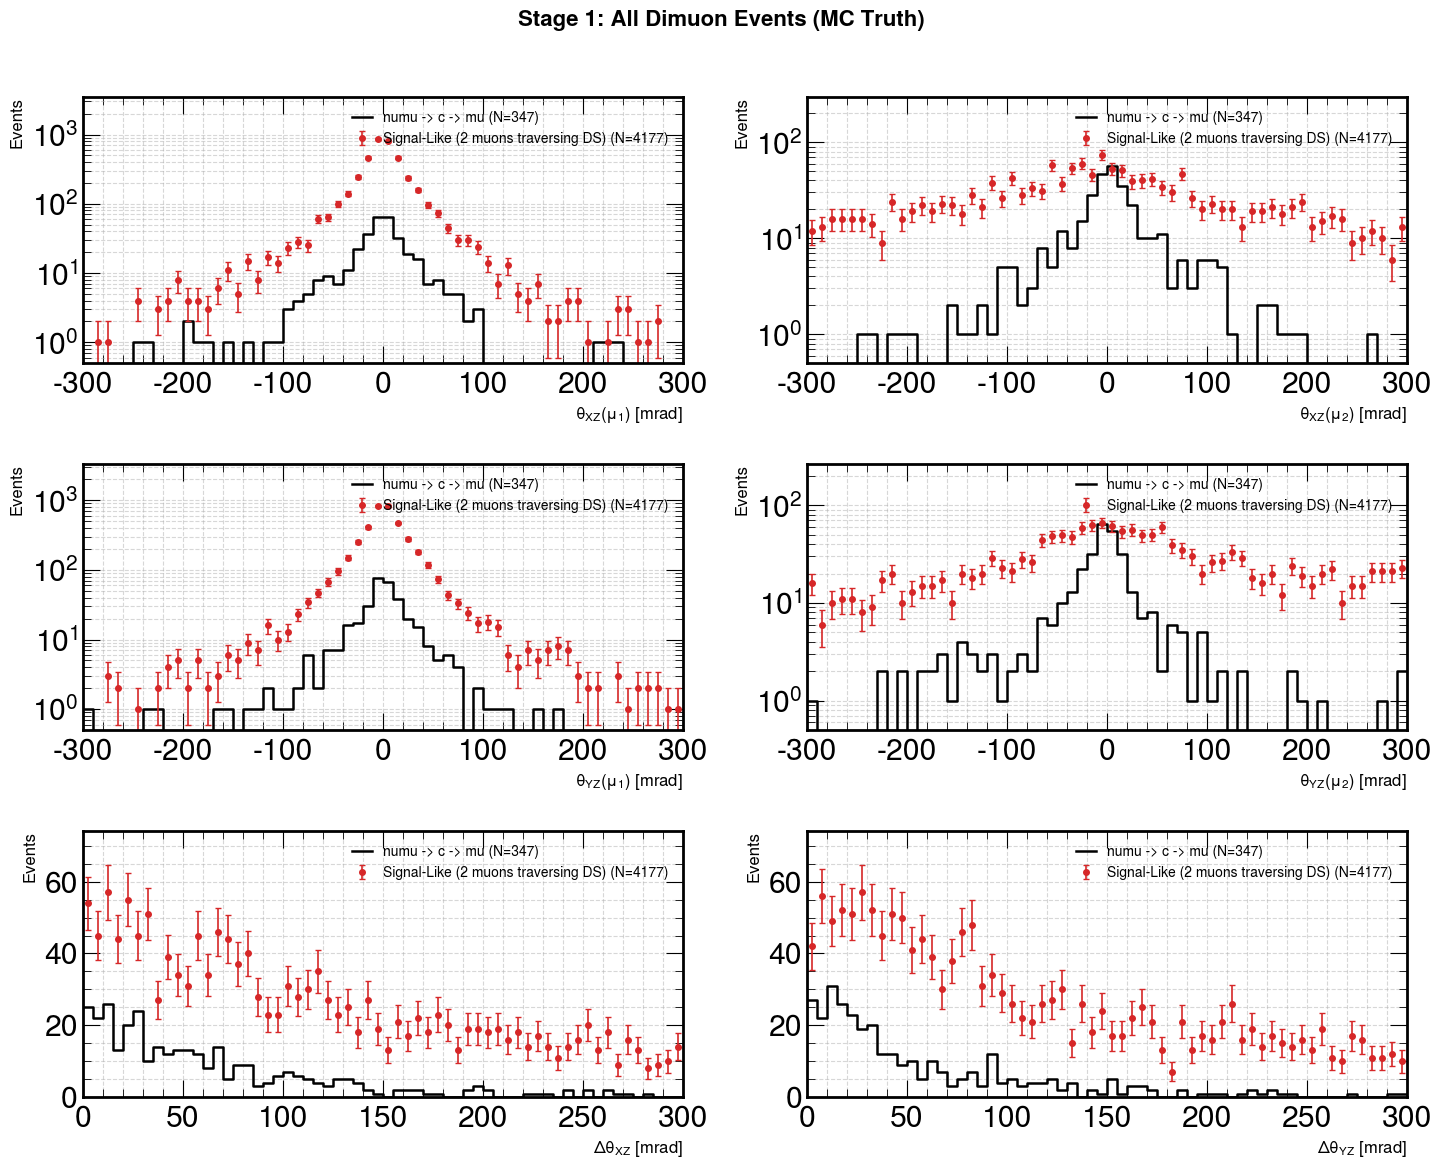

In [6]:
# Plot Stage 1: All Dimuon Events (theta_XZ, theta_YZ, and Delta theta)
if tfile:
    fig1, axes1 = plot_stage_angular_distributions(
        input_file=tfile,
        stage=1,
        sig_label="numu -> c -> mu",
        bkg_label="Signal-Like (2 muons traversing DS)",
    )
    plt.show()


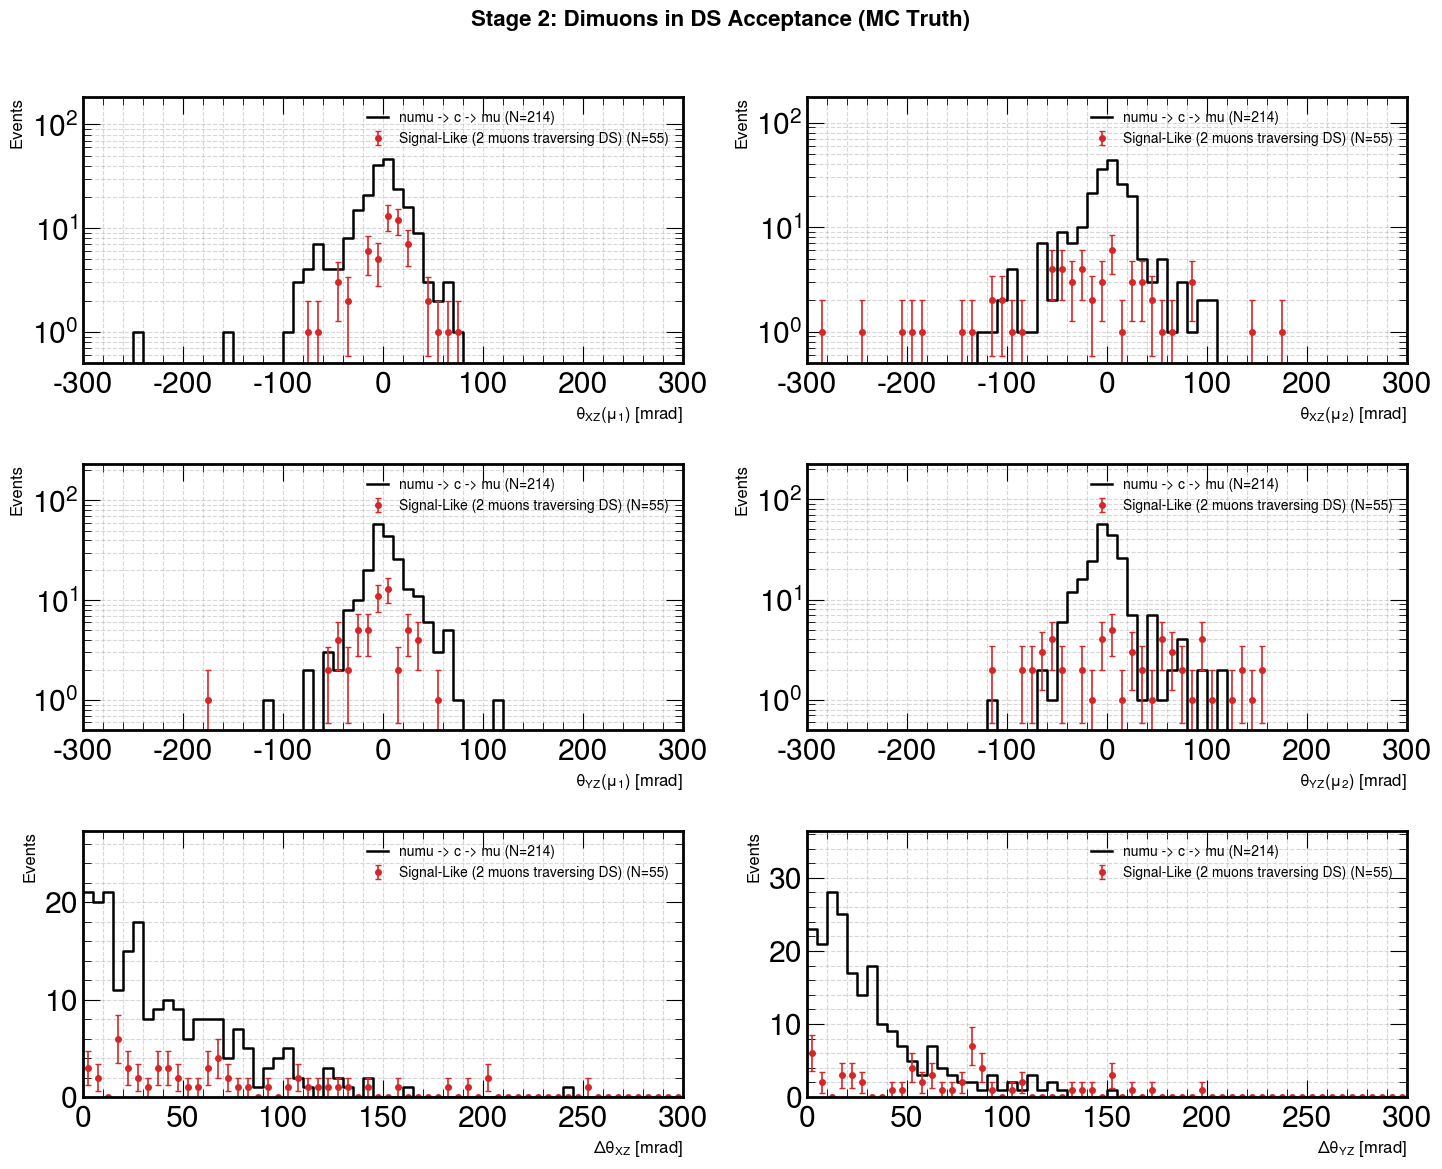

In [7]:
# Plot Stage 2: In DS Acceptance
if tfile:
    fig2, axes2 = plot_stage_angular_distributions(
        input_file=tfile,
        stage=2,
        sig_label="numu -> c -> mu",
        bkg_label="Signal-Like (2 muons traversing DS)",
    )
    plt.show()


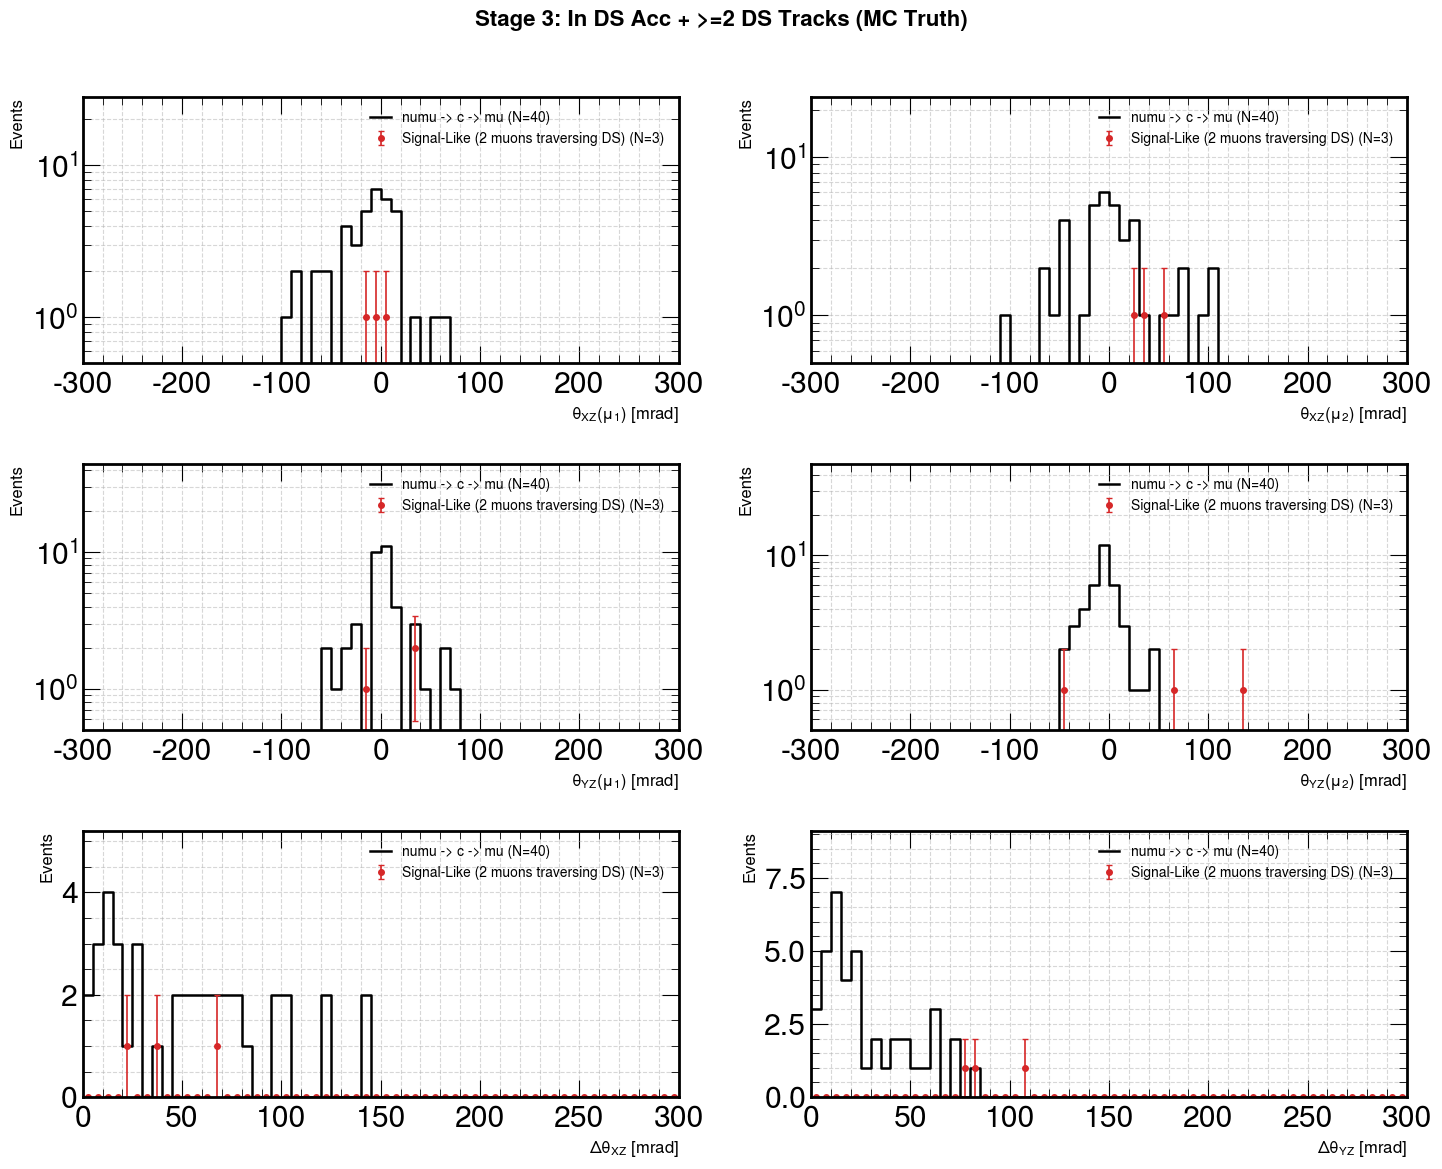

In [8]:
# Plot Stage 3: In DS Acceptance + >=2 DS Tracks (MC Truth Angles)
if tfile:
    fig3, axes3 = plot_stage_angular_distributions(
        input_file=tfile,
        stage=3,
        sig_label="numu -> c -> mu",
        bkg_label="Signal-Like (2 muons traversing DS)",
    )
    plt.show()


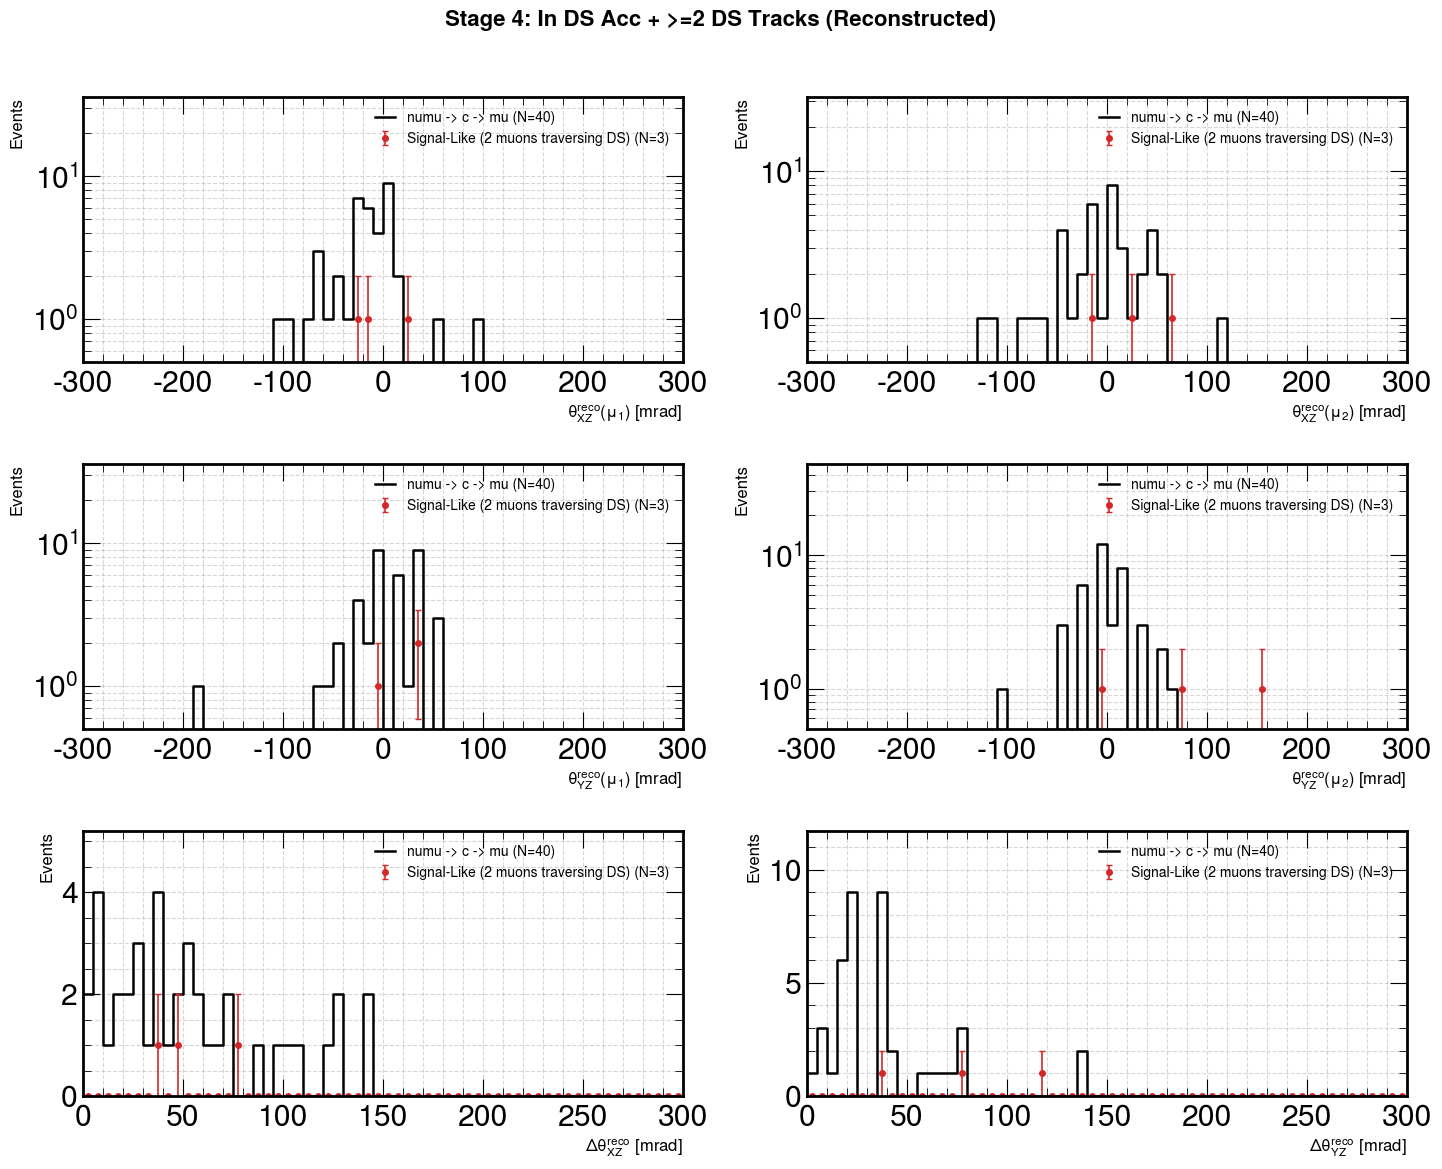

In [9]:
# Plot Stage 4: In DS Acceptance + >=2 DS Tracks (Reconstructed Track Angles)
if tfile:
    fig4, axes4 = plot_stage_angular_distributions(
        input_file=tfile,
        stage=4,
        sig_label="numu -> c -> mu",
        bkg_label="Signal-Like (2 muons traversing DS)",
    )
    plt.show()


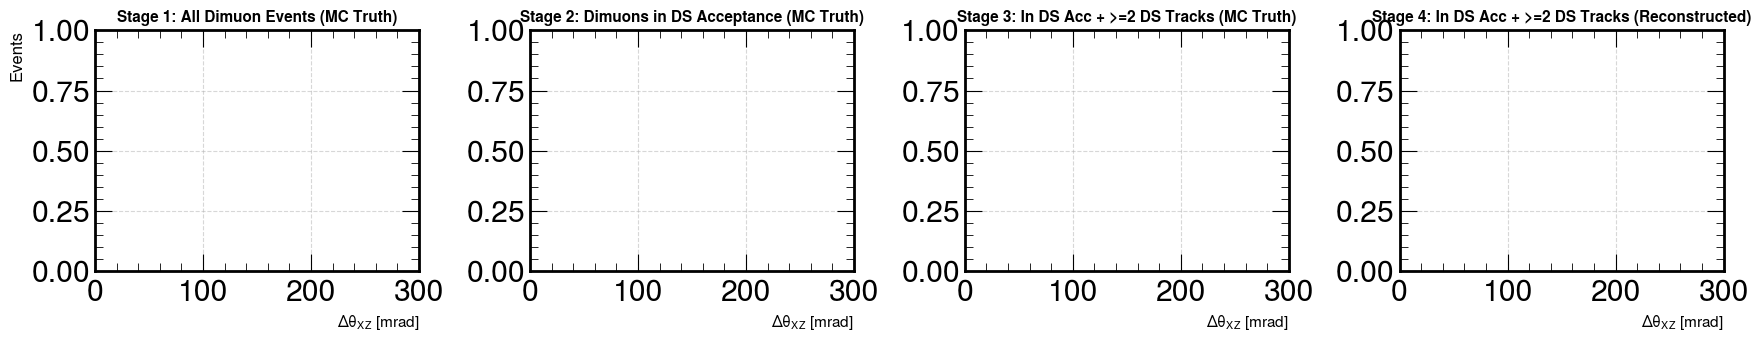

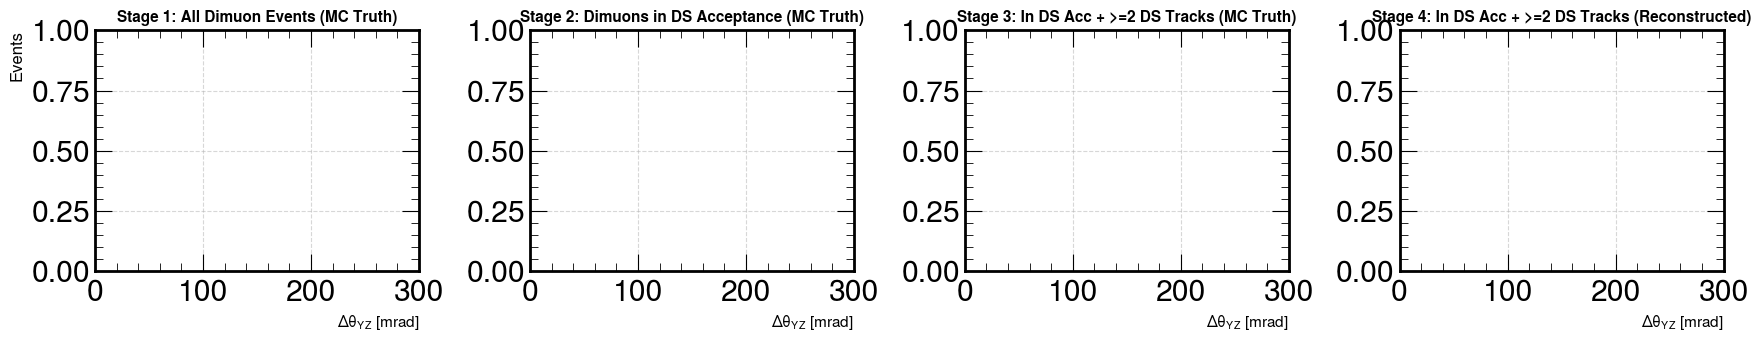

In [10]:
# -------------------------------------------------------------------------
# Stage Evolution Plots: Comparing Stages 1 to 4 Side-by-Side
# -------------------------------------------------------------------------
if tfile:
    # 1. Primary Prompt Muon Angle theta_XZ(mu_1)
    fig_evo_mu1_xz, _ = plot_all_stages_evolution(
        input_file=tfile,
        observable="mu1_theta_xz_mrad",
        obs_label=r"$\theta_{XZ}(\mu_1)$ [mrad]",
        is_log=True,
        xlim=(-300, 300),
    )
    plt.show()

    # 2. Primary Prompt Muon Angle theta_YZ(mu_1)
    fig_evo_mu1_yz, _ = plot_all_stages_evolution(
        input_file=tfile,
        observable="mu1_theta_yz_mrad",
        obs_label=r"$\theta_{YZ}(\mu_1)$ [mrad]",
        is_log=True,
        xlim=(-300, 300),
    )
    plt.show()

    # 3. Secondary Charm Decay Muon Angle theta_XZ(mu_2)
    fig_evo_mu2_xz, _ = plot_all_stages_evolution(
        input_file=tfile,
        observable="sec_mu_theta_xz_mrad",
        obs_label=r"$\theta_{XZ}(\mu_2)$ [mrad]",
        is_log=True,
        xlim=(-300, 300),
    )
    plt.show()

    # 4. Secondary Charm Decay Muon Angle theta_YZ(mu_2)
    fig_evo_mu2_yz, _ = plot_all_stages_evolution(
        input_file=tfile,
        observable="sec_mu_theta_yz_mrad",
        obs_label=r"$\theta_{YZ}(\mu_2)$ [mrad]",
        is_log=True,
        xlim=(-300, 300),
    )
    plt.show()

    # 5. Dimuon Opening Angle Delta theta_XZ
    fig_evo_xz, _ = plot_all_stages_evolution(
        input_file=tfile,
        observable="dimuon_opening_angle_xz_mrad",
        obs_label=r"$\Delta\theta_{XZ}$ [mrad]",
        is_log=False,
        xlim=(0, 300),
    )
    plt.show()

    # 6. Dimuon Opening Angle Delta theta_YZ
    fig_evo_yz, _ = plot_all_stages_evolution(
        input_file=tfile,
        observable="dimuon_opening_angle_yz_mrad",
        obs_label=r"$\Delta\theta_{YZ}$ [mrad]",
        is_log=False,
        xlim=(0, 300),
    )
    plt.show()


## 5. Selection and Reconstruction Efficiency vs Neutrino Energy

Visualizing the sequential selection stages as a function of incoming neutrino energy $E_\nu$:
- **Top Subplot**: Fraction of all events (DS Acceptance and 2 Reconstructed DS Tracks)
- **Bottom Subplot**: Tracking efficiency given DS acceptance $\epsilon(2\,\mathrm{DS} \mid \mathrm{In\,Acc})$ with integrated baseline
- Variable bin edges: `(0, 100, 200, 300, 400, 500, 600, 725, 850, 1200, 1600)` GeV


In [ ]:
def extract_rebinned_teff(teff_path: str, tfile, rebin: int = 1, ylim1=(0, 1.05), ylim2=(None, None)):
    """
    Extract TEfficiency data with rebinning and Clopper-Pearson 1-sigma intervals.
    
    Args:
        teff_path: In-file path to TEfficiency object.
        tfile: Open ROOT.TFile.
        rebin: Factor to rebin neighbouring bins (default 1 -> preserves variable/booked bins).
    """
    teff = tfile.Get(teff_path)
    if not teff:
        return None
        
    hp = teff.GetPassedHistogram().Clone()
    ht = teff.GetTotalHistogram().Clone()
    tot_p = hp.Integral(0, hp.GetNbinsX() + 1)
    tot_t = ht.Integral(0, ht.GetNbinsX() + 1)
    
    if rebin > 1:
        hp.Rebin(rebin)
        ht.Rebin(rebin)
        
    teff_reb = ROOT.TEfficiency(hp, ht)
    teff_reb.SetStatisticOption(ROOT.TEfficiency.kFCP)
    
    xs, x_errs, effs, y_err_lows, y_err_highs = [], [], [], [], []
    for b in range(1, hp.GetNbinsX() + 1):
        t = ht.GetBinContent(b)
        if t <= 0:
            continue
        xs.append(hp.GetBinCenter(b))
        x_errs.append(hp.GetBinWidth(b) / 2.0)
        effs.append(teff_reb.GetEfficiency(b))
        y_err_lows.append(teff_reb.GetEfficiencyErrorLow(b))
        y_err_highs.append(teff_reb.GetEfficiencyErrorUp(b))
        
    return {
        'x': np.array(xs),
        'x_err': np.array(x_errs),
        'eff': np.array(effs),
        'y_err': [np.array(y_err_lows), np.array(y_err_highs)],
        'tot_p': tot_p,
        'tot_t': tot_t,
        'tot_eff': (tot_p / tot_t) if tot_t > 0 else 0.0
    }


def plot_stacked_efficiency_figure(
    cat: str,
    tfile,
    rebin: int = 1,
    figsize: tuple = (10, 8),
    xlim: tuple = (0, 1600),
    show_plot: bool = True
):
    """
    Plot 2-panel stacked figure matching the slide layout:
      Top panel: Fraction of All Events vs E_nu
        - Blue squares: In DS Acceptance: {p_acc}/{t_acc} ({pct_acc:.1f}%)
        - Black diamonds: 2 DS Tracks: {p_ov}/{t_ov} ({pct_ov:.1f}%)
        - Summary box: Category, All events, Two muons in DS acc, Two DS tracks
      Bottom panel: Tracking Efficiency eps(2 DS | In Acc) vs E_nu
        - Teal triangles: Tracking Efficiency eps(2 DS | In Acc): {p_in}/{t_in} ({pct_in:.1f}%)
        - Dotted horizontal line at integrated efficiency
        - Shared x-axis: Neutrino energy E_nu [GeV]
    """
    cat_meta = {
        'direct': {
            'title': r'$\nu_\mu \to c \to \mu$ (Signal)',
            'short_title': 'Signal'
        },
        'indirect': {
            'title': r'$\nu_\mu \to c \to \mathrm{hadrons} \to \mu$ (Fake Signal)',
            'short_title': 'Fake Signal'
        },
        'non_charm': {
            'title': r'Other Backgrounds (Non-Charm Dimuons)',
            'short_title': 'Other Bkg'
        }
    }
    meta = cat_meta.get(cat, {'title': cat, 'short_title': cat})
    
    # 1. DS Acceptance: (b) / (a)
    d_acc = extract_rebinned_teff(
        f'efficiencies_clopper_pearson/ds_acceptance/teff_ds_acc_{cat}_vs_nu_e',
        tfile, rebin=rebin
    )
    # 2. Two DS tracks overall: (c) / (a)
    d_ov = extract_rebinned_teff(
        f'efficiencies_clopper_pearson/two_ds_tracks_overall/teff_2ds_overall_{cat}_vs_nu_e',
        tfile, rebin=rebin
    )
    # 3. Two DS tracks in DS acceptance: (c) / (b)
    d_in_acc = extract_rebinned_teff(
        f'efficiencies_clopper_pearson/two_ds_tracks_in_ds_acceptance/teff_2ds_in_acc_{cat}_vs_nu_e',
        tfile, rebin=rebin
    )
    
    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=figsize, sharex=True,
        gridspec_kw={'height_ratios': [1.2, 0.8], 'hspace': 0.08}
    )
    
    p_ov = int(round(d_ov['tot_p'])) if d_ov else 0
    t_ov = int(round(d_ov['tot_t'])) if d_ov else 0
    pct_ov = d_ov['tot_eff'] * 100 if d_ov else 0.0
    
    p_acc = int(round(d_acc['tot_p'])) if d_acc else 0
    t_acc = int(round(d_acc['tot_t'])) if d_acc else 0
    pct_acc = d_acc['tot_eff'] * 100 if d_acc else 0.0
    
    p_in = int(round(d_in_acc['tot_p'])) if d_in_acc else 0
    t_in = int(round(d_in_acc['tot_t'])) if d_in_acc else 0
    pct_in = d_in_acc['tot_eff'] * 100 if d_in_acc else 0.0
    
    # --- Top Subplot: Fraction of All Events ---
    if d_acc and len(d_acc['x']) > 0:
        ax_top.errorbar(
            d_acc['x'], d_acc['eff'],
            xerr=d_acc['x_err'], yerr=d_acc['y_err'],
            fmt='s', color='#1f77b4', ecolor='#1f77b4', elinewidth=1.6, capsize=0, markersize=6,
            label=rf'In DS Acceptance: {p_acc}/{t_acc} ({pct_acc:.1f}%)'
        )
    if d_ov and len(d_ov['x']) > 0:
        ax_top.errorbar(
            d_ov['x'], d_ov['eff'],
            xerr=d_ov['x_err'], yerr=d_ov['y_err'],
            fmt='D', color='#1a1a1a', ecolor='#1a1a1a', elinewidth=1.6, capsize=0, markersize=5,
            label=rf'2 DS Tracks: {p_ov}/{t_ov} ({pct_ov:.1f}%)'
        )
        
    txt_top = (
        f"{meta['title']}\n"
        f"All events: {t_ov}\n"
        f"Two muons in DS acc: {p_acc}/{t_ov} ({pct_acc:.1f}%)\n"
        f"Two DS tracks: {p_ov}/{t_ov} ({pct_ov:.1f}% of all, {pct_in:.1f}% of in-acc)"
    )
    ax_top.text(
        0.03, 0.95, txt_top, transform=ax_top.transAxes,
        fontsize=11, verticalalignment='top',
        bbox=dict(boxstyle='square,pad=0.4', facecolor='white', alpha=0.9, edgecolor='lightgray', linewidth=0.8)
    )
    ax_top.set_ylabel('Fraction of All Events', fontsize=13)
    ax_top.set_ylim(ylim1)
    ax_top.set_xlim(xlim)
    ax_top.legend(loc='upper right', frameon=True, fontsize=10.5)
    ax_top.grid(True, linestyle='--', alpha=0.3)
    ax_top.tick_params(labelbottom=False)
    
    # --- Bottom Subplot: Tracking Efficiency given Acceptance ---
    if d_in_acc and len(d_in_acc['x']) > 0:
        ax_bot.errorbar(
            d_in_acc['x'], d_in_acc['eff'],
            xerr=d_in_acc['x_err'], yerr=d_in_acc['y_err'],
            fmt='^', color='#2a9d8f', ecolor='#2a9d8f', elinewidth=1.6, capsize=0, markersize=6,
            label=rf'Tracking Efficiency $\epsilon$(2 DS | In Acc): {p_in}/{t_in} ({pct_in:.1f}%)'
        )
        ax_bot.axhline(d_in_acc['tot_eff'], color='#2a9d8f', linestyle=':', linewidth=1.4, alpha=0.8)
        
    ax_bot.set_ylabel(r'$\epsilon_{\mathrm{reco|acc}}$', fontsize=13)
    ax_bot.set_xlabel(r'Neutrino energy $E_\nu$ [GeV]', fontsize=13)
    max_in = max(d_in_acc['eff']) if (d_in_acc and len(d_in_acc['eff']) > 0) else 0.5
    ax_bot.set_ylim(ylim2)
    ax_bot.set_xlim(xlim)
    ax_bot.legend(loc='upper right', frameon=True, fontsize=10.5)
    ax_bot.grid(True, linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    if show_plot:
        plt.show()
    else:
        plt.close()
    return fig, (ax_top, ax_bot)


/tmp/ipykernel_39579/2689411747.py:125: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


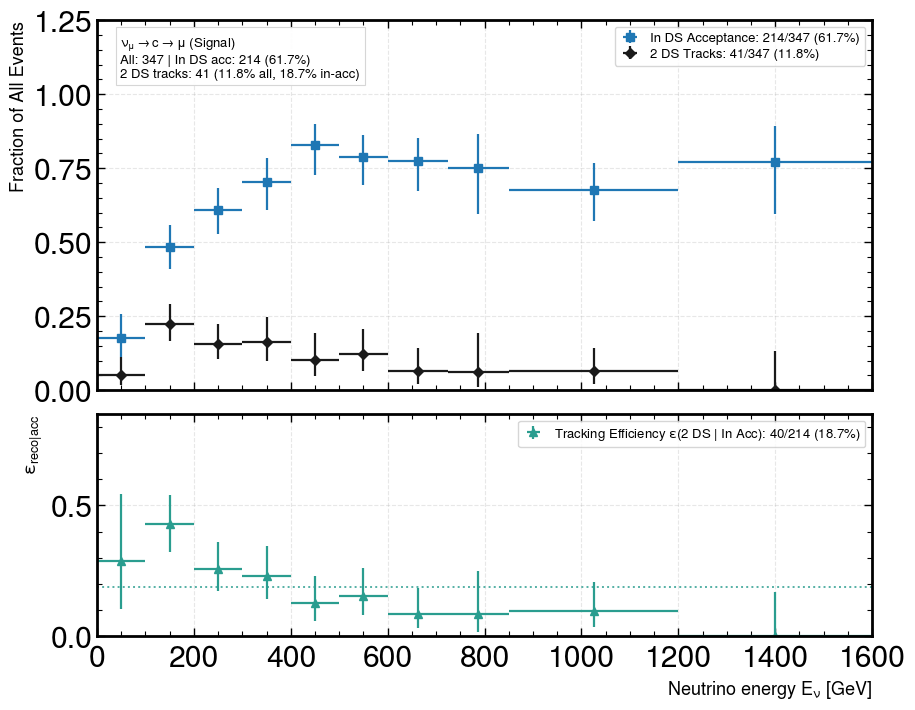

In [16]:
# Figure 1: Direct Signal (numu -> c -> mu)
# Plots (a) all signal events, (b) signal events with 2 muons in DS acc, (c) signal events with 2 reconstructed DS tracks
if tfile:
    fig_sig, (ax_sig_top, ax_sig_bot) = plot_stacked_efficiency_figure("direct", tfile, rebin=1, xlim=(0, 1600))


/tmp/ipykernel_39579/448206856.py:168: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


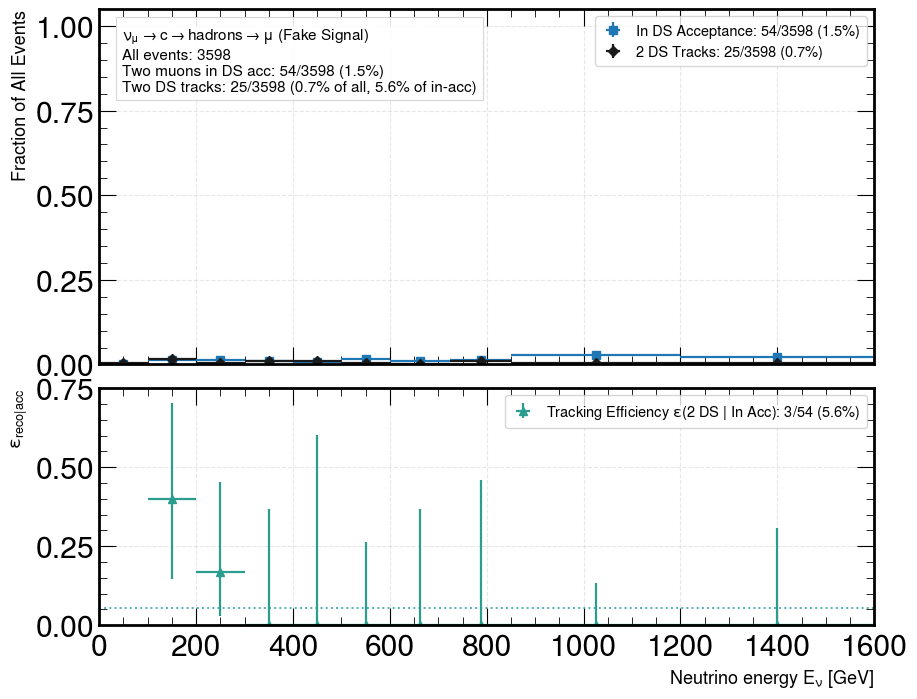

In [13]:
# Figure 2: Fake Signal (numu -> c -> hadrons -> mu)
# Plots (a) all fake signal events, (b) with 2 muons in DS acc, (c) with 2 reconstructed DS tracks
if tfile:
    fig_fake, (ax_fake_top, ax_fake_bot) = plot_stacked_efficiency_figure("indirect", tfile, rebin=1, xlim=(0, 1600))


/tmp/ipykernel_39579/448206856.py:168: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


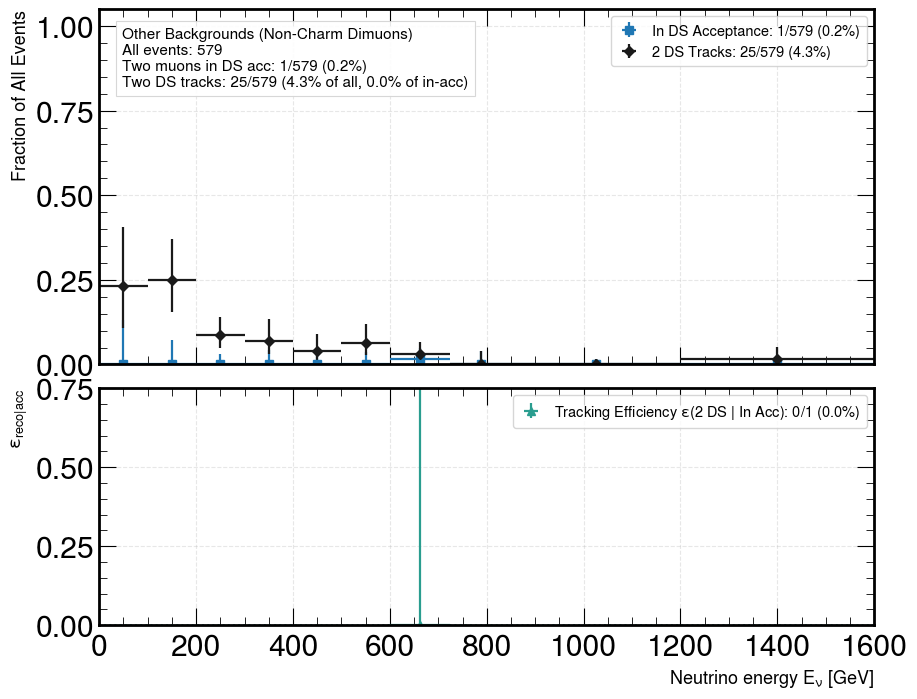

In [14]:
# Figure 3: Other Backgrounds (Non-Charm Dimuons)
# Plots (a) all other bkg events, (b) with 2 muons in DS acc, (c) with 2 reconstructed DS tracks
if tfile:
    fig_bkg, (ax_bkg_top, ax_bkg_bot) = plot_stacked_efficiency_figure("non_charm", tfile, rebin=1, xlim=(0, 1600))
